# LLM query router: MLP probe demo (pilot)

- Snapshot: saved outputs are from the 400-question pilot
- `results/` now holds the full 17,032-question run -> re-running gives full-data numbers
- Current results: `full_demo.ipynb`

- Router: per question, cheap Llama 3.1 8B or expensive Llama 3.3 70B?
- Goal: most questions answered cheaply, little accuracy lost
- Data: pilot, 200 MATH + 200 MMLU-Pro

1. The data
2. Embeddings
3. Training the probe
4. Routing a question
5. Accuracy-vs-cost curve
6. Choosing an operating point
7. Failure analysis

In [1]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '..')
import mlp_probe as mp

%matplotlib inline
pd.set_option('display.max_colwidth', 120)

## 1. The data

- Both models answered every question once
- Per question: 8B right/wrong, 70B right/wrong, cost of each

In [2]:
df = mp.load()
C = df[mp.MODELS].to_numpy(int)
K = df[[f'cost_{m}' for m in mp.MODELS]].to_numpy(float)
L = df[[f'latency_{m}' for m in mp.MODELS]].to_numpy(float)
df[['dataset', 'subject', 'llama-8b', 'llama-70b', 'cost_llama-8b', 'cost_llama-70b']].head()

,dataset,subject,llama-8b,llama-70b,cost_llama-8b,cost_llama-70b
qid,,,,,,
math_0,math,Intermediate Algebra,0,1,0.000008,0.000107
math_1,math,Counting & Probability,0,0,0.000008,0.000143
math_10,math,Precalculus,0,0,0.000022,0.000329
math_100,math,Intermediate Algebra,1,0,0.000011,0.000335
math_101,math,Intermediate Algebra,0,1,0.000043,0.000150


- 4 groups per question
- Only "only 70B solves" is worth paying for
- "Neither solves" -> 8B (no router can help)

In [3]:
c, e = df['llama-8b'], df['llama-70b']
groups = pd.Series(np.select([(c == 1) & (e == 1), (c == 1) & (e == 0), (c == 0) & (e == 1)],
                             ['both solve', 'only 8B solves', 'only 70B solves'], 'neither solves'),
                   index=df.index, name='group')
pd.crosstab(df.dataset, groups, normalize='index', margins=True).round(3)

group,both solve,neither solves,only 70B solves,only 8B solves
dataset,,,,
math,0.285,0.285,0.400,0.030
mmlupro,0.370,0.245,0.330,0.055
All,0.328,0.265,0.365,0.042


- Oracle = perfect router
- Cheapest correct model; 8B if neither is correct

In [4]:
n_all = len(df)
base_all = {
    'always 8B': mp.metrics(np.zeros(n_all, int), C, K, L),
    'always 70B': mp.metrics(np.ones(n_all, int), C, K, L),
    'oracle': mp.metrics(mp.oracle_choice(C), C, K, L),
}
pd.DataFrame(base_all).T[['task_acc', 'cost_frac', 'frac_llama-70b', 'latency_s']].round(3)

,task_acc,cost_frac,frac_llama-70b,latency_s
always 8B,0.370,0.097,0.000,8.011
always 70B,0.692,1.000,1.000,18.623
oracle,0.735,0.424,0.365,11.405


- `cost_frac` = cost / always-70B cost
- Target: within 3 pts of always-70B, <= 40% of its cost
- Oracle needs ~42% -> target just out of reach even for a perfect router
- So also compare: distance to the oracle curve

## 2. Embeddings

- Frozen `all-MiniLM-L6-v2` -> 384 numbers per question
- Only the probe on top is trained

In [5]:
X = mp.embeddings(df)
print('embedding matrix:', X.shape)
example = df.index[0]
print(f'\n{example} ({df.dataset[example]}):\n{df.text[example][:300]}')
print('\nfirst 8 of its 384 numbers:', np.round(X[0, :8], 3))

embedding matrix: (400, 384)

math_0 (math):
If $y=\frac{27x^2+9x+3}{27x^3+9x^2+3x+1}$, at what value of $y$ will there be a horizontal asymptote?

first 8 of its 384 numbers: [-0.024  0.018 -0.04   0.043  0.022  0.032 -0.086  0.049]


- PCA of all 400 questions
- Separates by dataset (topic)
- Groups (difficulty) all mixed

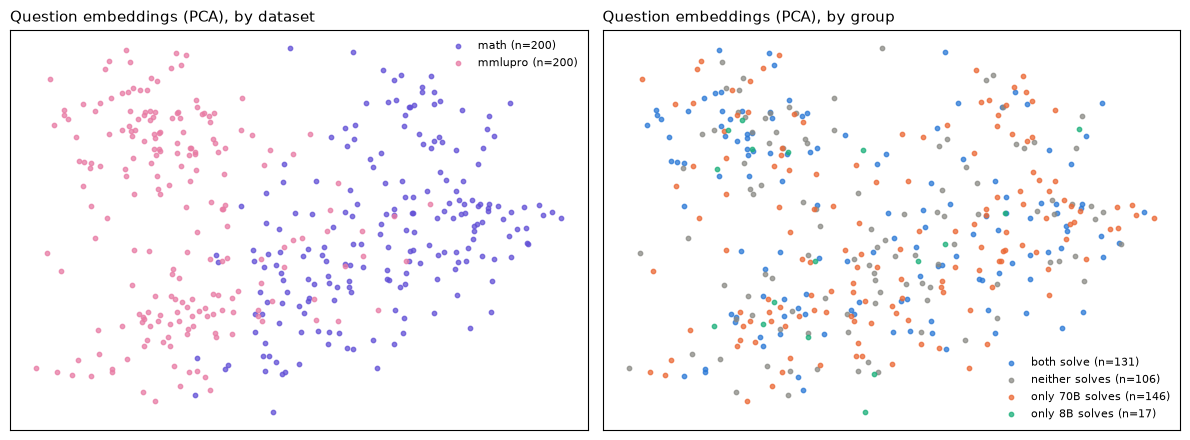

In [6]:
from sklearn.decomposition import PCA

xy = PCA(2, random_state=0).fit_transform(X)
colors = {'both solve': '#2a78d6', 'only 8B solves': '#1baf7a', 'only 70B solves': '#eb6834',
          'neither solves': '#8a8a85'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, key) in zip(axes, [('by dataset', df.dataset), ('by group', groups)]):
    for i, (lab, m) in enumerate(key.groupby(key).groups.items()):
        pts = xy[df.index.get_indexer(m)]
        ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.75, label=f'{lab} (n={len(m)})',
                   color=colors.get(lab, ['#6250d6', '#e87ba4'][i % 2]))
    ax.set_title(f'Question embeddings (PCA), {title}', loc='left', fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 3. Training the probe

- Split 60/20/20 train/val/test, stratified by dataset
- 384 -> hidden -> 2: P(8B correct), P(70B correct)
- Loss: BCE summed over both models; Adam, early stopping
- 3 seeds, hyperparameters from `mlp_probe.py`

In [7]:
S = {s: (df.split == s).to_numpy() for s in mp.SPLIT}
tr, va, te = S['train'], S['val'], S['test']
print({s: int(m.sum()) for s, m in S.items()})

mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
Z = (X - mu) / sd

hp = json.loads((mp.OUT / 'summary.json').read_text())['hyperparameters']
print('hyper-parameters:', hp)
nets = [mp.train(Z[tr], C[tr], Z[va], C[va], seed=s, **hp)[0] for s in mp.SEEDS]
P = mp.predict(nets, Z)
print('predictions:', P.shape, '-> columns: P(8B correct), P(70B correct)')

{'train': 240, 'val': 80, 'test': 80}
hyper-parameters: {'hidden': 32, 'lr': 0.001, 'weight_decay': 0.001, 'dropout': 0.3}


predictions: (400, 2) -> columns: P(8B correct), P(70B correct)


Sample test predictions:

In [8]:
preview = df.loc[te, ['dataset', 'subject', 'llama-8b', 'llama-70b']].copy()
preview['P(8B correct)'] = P[te, 0].round(2)
preview['P(70B correct)'] = P[te, 1].round(2)
preview.head(10)

,dataset,subject,llama-8b,llama-70b,P(8B correct),P(70B correct)
qid,,,,,,
math_104,math,Algebra,1,1,0.36,0.66
math_109,math,Algebra,0,1,0.57,0.75
math_110,math,Prealgebra,1,1,0.55,0.78
math_121,math,Counting & Probability,0,0,0.49,0.58
math_124,math,Counting & Probability,0,1,0.63,0.66
math_126,math,Intermediate Algebra,0,0,0.54,0.64
math_127,math,Algebra,0,1,0.42,0.74
math_128,math,Prealgebra,0,0,0.45,0.36
math_14,math,Geometry,0,1,0.55,0.66


Test AUROC per head:

In [9]:
from sklearn.metrics import roc_auc_score

print(f"test AUROC, 8B head: {roc_auc_score(C[te, 0], P[te, 0]):.3f}")
print(f"test AUROC, 70B head: {roc_auc_score(C[te, 1], P[te, 1]):.3f}")

test AUROC, 8B head: 0.554
test AUROC, 70B head: 0.593


## 4. Routing a question

- Threshold rule: P(8B) > t -> 8B, else 70B (t: 0 to 1)
- Gain rule: P(70B) - P(8B) > t -> 70B, else 8B (t: -1 to 1)
- Example: one test question

In [10]:
q = df.index[te][0]
i = df.index.get_loc(q)
print(df.text[q][:400], '\n')
print(f'P(8B correct) = {P[i, 0]:.2f}   P(70B correct) = {P[i, 1]:.2f}')
print(f"truth: 8B {'right' if C[i, 0] else 'wrong'}, 70B {'right' if C[i, 1] else 'wrong'}\n")
for t in (0.3, 0.5, 0.7):
    print(f't = {t}: threshold rule -> {mp.MODELS[mp.route(P[i:i + 1], t)[0]]:9s}  '
          f'gain rule -> {mp.MODELS[mp.route_gain(P[i:i + 1], t - 0.5)[0]]} (gain t = {t - 0.5:+.1f})')

Let $f(x) = 2x+1$ and $g(x) = f(2x) - 3$. What is $g(g(2))$? 

P(8B correct) = 0.36   P(70B correct) = 0.66
truth: 8B right, 70B right

t = 0.3: threshold rule -> llama-8b   gain rule -> llama-70b (gain t = -0.2)
t = 0.5: threshold rule -> llama-70b  gain rule -> llama-70b (gain t = +0.0)
t = 0.7: threshold rule -> llama-70b  gain rule -> llama-70b (gain t = +0.2)


## 5. Accuracy-vs-cost curve

- Sweep t: always-8B -> always-70B
- Good router: climbs steeply toward the oracle
- Baselines: random (20 seeds), length (longest -> 70B first)

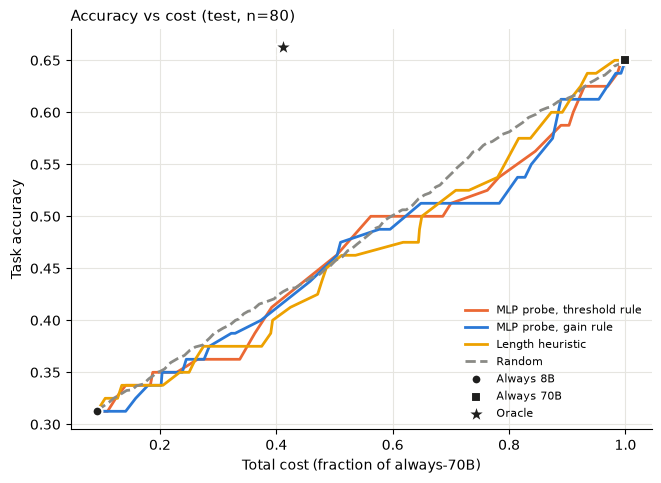

In [11]:
Ct, Kt, Lt = C[te], K[te], L[te]
n = len(Ct)
curve = mp.sweep(P[te], Ct, Kt, Lt)
gain_curve = mp.sweep(P[te], Ct, Kt, Lt, rule=mp.route_gain, ts=mp.GAIN_TS)
rand = pd.concat([mp.sweep(np.random.default_rng(s).uniform(size=(n, 2)), Ct, Kt, Lt)
                  for s in range(20)]).groupby('t', as_index=False).mean()
train_len = np.sort(df.text[tr].str.len().to_numpy())
pct = np.searchsorted(train_len, df.text[te].str.len().to_numpy(), side='right') / (len(train_len) + 1)
length = mp.sweep(np.stack([1 - pct, np.ones(n)], 1), Ct, Kt, Lt)
base = {'always_cheapest': mp.metrics(np.zeros(n, int), Ct, Kt, Lt),
        'always_most_expensive': mp.metrics(np.ones(n, int), Ct, Kt, Lt),
        'oracle': mp.metrics(mp.oracle_choice(Ct), Ct, Kt, Lt)}

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for c_, color, label, ls in [(curve, '#eb6834', 'MLP probe, threshold rule', '-'),
                             (gain_curve, '#2a78d6', 'MLP probe, gain rule', '-'),
                             (length, '#eda100', 'Length heuristic', '-'),
                             (rand, '#8a8a85', 'Random', '--')]:
    ax.plot(c_.cost_frac, c_.task_acc, color=color, lw=2, ls=ls, label=label)
for name, marker, label in [('always_cheapest', 'o', 'Always 8B'), ('always_most_expensive', 's', 'Always 70B'),
                            ('oracle', '*', 'Oracle')]:
    ax.scatter(base[name]['cost_frac'], base[name]['task_acc'], marker=marker, s=200 if marker == '*' else 50,
               color='#1f1f1e', edgecolor='white', lw=1.5, zorder=5, label=label)
ax.set_xlabel('Total cost (fraction of always-70B)')
ax.set_ylabel('Task accuracy')
ax.set_title(f'Accuracy vs cost (test, n={n})', loc='left', fontsize=11)
ax.grid(True, color='#e6e5e0'); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='lower right');

Gap to oracle curve (lower = better):

In [12]:
pd.Series({'MLP, threshold rule': mp.oracle_gap(curve, Ct, Kt),
           'MLP, gain rule': mp.oracle_gap(gain_curve, Ct, Kt),
           'Length heuristic': mp.oracle_gap(length, Ct, Kt),
           'Random': mp.oracle_gap(rand, Ct, Kt)}, name='gap to oracle curve').round(3).to_frame()

,gap to oracle curve
"MLP, threshold rule",0.142
"MLP, gain rule",0.142
Length heuristic,0.140
Random,0.122


## 6. Choosing an operating point

- t = cheapest within 3 pts of always-70B on val
- Applied unchanged to test

In [13]:
acc_exp_val = C[va, 1].mean()
rows = {}
for label, rule, ts in [('threshold rule', mp.route, None), ('gain rule', mp.route_gain, mp.GAIN_TS)]:
    t = mp.pick_t(mp.sweep(P[va], C[va], K[va], L[va], rule=rule, ts=ts), acc_exp_val)
    m = mp.metrics(rule(P[te], t), Ct, Kt, Lt)
    gap = 100 * (base['always_most_expensive']['task_acc'] - m['task_acc'])
    rows[f'MLP, {label}'] = {'t*': t, 'test acc': m['task_acc'], 'gap to 70B (pts)': gap,
                             'cost frac': m['cost_frac'], 'sent to 70B': m['frac_llama-70b'],
                             'routing acc': m['routing_acc'],
                             'meets target': gap <= mp.TARGET_GAP and m['cost_frac'] <= mp.TARGET_COST}
pd.DataFrame(rows).T

,t*,test acc,gap to 70B (pts),cost frac,sent to 70B,routing acc,meets target
"MLP, threshold rule",0.61,0.625,2.5,0.948128,0.9375,0.3625,False
"MLP, gain rule",0.03,0.575,7.5,0.874856,0.85,0.35,False


## 7. Failure analysis

- At chosen t
- Optimal: same as oracle
- Under-routed: -> 8B, only 70B solves (accuracy lost)
- Over-routed: -> 70B, 8B solves (money wasted)
- No model solves

In [14]:
t_star = rows['MLP, threshold rule']['t*']
ch, orc = mp.route(P[te], t_star), mp.oracle_choice(Ct)
outcome = pd.Series(np.select([~Ct.any(1), ch == orc, ch < orc],
                              ['no model solves', 'optimal', 'under-routed'], 'over-routed'),
                    index=df.index[te], name='outcome')
pd.crosstab(df.dataset[te], outcome, margins=True)

outcome,no model solves,optimal,over-routed,under-routed,All
dataset,,,,,
math,12,14,12,2,40
mmlupro,15,13,12,0,40
All,27,27,24,2,80


In [15]:
over = outcome[outcome == 'over-routed'].index[:3]
for q in over:
    i = df.index.get_loc(q)
    print(f'[{df.dataset[q]} / {df.subject[q]}]  P(8B correct) = {P[i, 0]:.2f}  -> sent to 70B, but the 8B was right')
    print('  ', df.text[q][:200].replace('\n', ' '), '\n')

[math / Algebra]  P(8B correct) = 0.36  -> sent to 70B, but the 8B was right
   Let $f(x) = 2x+1$ and $g(x) = f(2x) - 3$. What is $g(g(2))$? 

[math / Prealgebra]  P(8B correct) = 0.55  -> sent to 70B, but the 8B was right
   What is the value of $6 + (8 \div 2)$? 

[math / Prealgebra]  P(8B correct) = 0.50  -> sent to 70B, but the 8B was right
   The measures of the angles of a triangle are in a ratio of $3:5:7$. What is the degree measure of the largest angle? 



## Takeaways

- Oracle: beats always-70B at ~42% cost -> routing worthwhile
- 240 training questions -> probe near chance (AUROC 0.55 / 0.59), ~ random routing
- Chosen t sends 94% to 70B
- Embeddings capture topic, not difficulty
- Next: more data (`full_demo.ipynb`), linear probe comparison